# HSA_Cam_B_020.py
This file uses the LHHW_Model of kinetics and FFD to determine kinetic parameters.

HSA_Cam_B_007.py is the model. This uses heteroscedastic noise of 10%  and exponential priors.

Analysis from the related python script.


In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpy as np
import matplotlib.pyplot as plt
import torch
import arviz as az
import ICIW_Plots

plt.style.use("ICIWstyle")

In [2]:
from HSA_Cam_B_018_pyro import (
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    kl_divergence_between_models,
)
from HSA_Mo_B_007_pyro import kinetics_model, sample_prior

In [3]:
def max_func(x, idata, key="posterior"):
    T = x[0].reshape(1, 1)
    p = x[1].reshape(1, 1)
    c2h = x[2].reshape(1, 1)
    f = x[3].reshape(1, 1)
    c2i = x[4].reshape(1, 1)
    p_i = calculate_partial_pressures(p, c2h, f, c2i)
    res = predict(
        idata,
        T,
        p_i,
        num_samples=1000,
        key=key,
    )
    HDI = torch.quantile(res, 0.975) - torch.quantile(res, 0.025)
    return -HDI

In [4]:
def evaluate_conditions(proposal, idata, key="posterior"):
    """
    Evaluate posterior predictions over temperature range at given conditions.

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions
        idata: ArviZ InferenceData with posterior samples

    Returns:
        predictions: Array of shape (100, n_samples) with rate predictions
    """
    # Extract conditions from proposal
    p = torch.tensor([[proposal[1]]])
    c2h = torch.tensor([[proposal[2]]])
    f = torch.tensor([[proposal[3]]])
    c2i = torch.tensor([[proposal[4]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, f, c2i)

    # Temperature range for evaluation
    T = torch.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # Generate posterior predictions
    predictions = predict(idata, T, p_i, key=key, num_samples=1000)

    return predictions


def evaluate_true_model(proposal):
    """
    Compute true model predictions (for comparison with posterior).

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions

    Returns:
        true_rates: Array of shape (100, 1) with true rate predictions
    """
    # Extract conditions
    p = torch.tensor([[proposal[1]]])
    c2h = torch.tensor([[proposal[2]]])
    f = torch.tensor([[proposal[3]]])
    c2i = torch.tensor([[proposal[4]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, f, c2i)

    # Temperature range
    T = torch.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # True model prediction
    _, _, true_rates = generate_synthetic_data(T, p, c2h, f, c2i, rel_noise_std=0.0)

    return true_rates.cpu().numpy()


def plot_predictions(fig, ax, proposal, posterior_preds, true_preds, T_range):
    """
    Visualize posterior predictions vs true model with uncertainty.

    Args:
        proposal: Experimental conditions [T, p, c2h, f, c2i]
        posterior_preds: Posterior predictions (100, n_samples)
        true_preds: True model predictions (100, 1)
        T_range: Temperature values for x-axis
    """

    # Posterior mean
    ax.plot(
        T_range,
        posterior_preds.mean(axis=1),
        label="Posterior Mean",
        # color="blue",
    )

    # True model
    ax.plot(
        T_range,
        true_preds.squeeze(),
        label="True Model",
        color="black",
        linestyle="--",
        linewidth=2,
    )

    # 95% credible interval
    ax.fill_between(
        T_range,
        np.percentile(posterior_preds, 2.5, axis=1),
        np.percentile(posterior_preds, 97.5, axis=1),
        alpha=0.3,
        # color="blue",
        label="95% HDI",
    )

    ax.legend(loc="upper left")

    # Add condition text
    # condition_text = (
    #     f"Conditions:\n"
    #     f"p = {proposal[1]:.1f} bar\n"
    #     f"CO2/H2 = {proposal[2]:.2f}\n"
    #     f"Feed ratio = {proposal[3]:.1f}\n"
    #     f"CO2/Inert = {proposal[4]:.2f}"
    # )
    # ax.text(
    #     0.02,
    #     0.8,
    #     condition_text,
    #     transform=ax.transAxes,
    #     fontsize=9,
    #     verticalalignment="top",
    #     bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5),
    # )

    # Second y-axis for HDI width
    # ax2 = ax.twinx()
    # hdi_width = np.percentile(posterior_preds, 97.5, axis=1) - np.percentile(
    #     posterior_preds, 2.5, axis=1
    # )
    # ax2.plot(T_range, hdi_width, color="orange", alpha=0.7, linewidth=2)
    # ax2.set_ylabel("HDI Width", color="orange")
    # ax2.tick_params(axis="y", labelcolor="orange")

    # plt.title("Posterior Predictions vs True Model")
    # plt.tight_layout()
    return fig, ax

In [5]:
exp_run_name = "blocky-seaplane"  # VI
data_path = Path(f"data/{exp_run_name}/")
sum_file = data_path / f"experiment_summary_{exp_run_name}.json"
trace_files = sorted(data_path.glob("trace_*.nc"))

In [6]:
idatas = []
for trace_file in trace_files:
    idata = az.from_netcdf(trace_file)
    idatas.append(idata)
    print(f"Loaded {trace_file}")
    print(idata.groups)

Loaded data\blocky-seaplane\trace_000.nc
<bound method InferenceData.groups of Inference data with groups:
	> posterior>
Loaded data\blocky-seaplane\trace_001.nc
<bound method InferenceData.groups of Inference data with groups:
	> posterior>
Loaded data\blocky-seaplane\trace_002.nc
<bound method InferenceData.groups of Inference data with groups:
	> posterior>
Loaded data\blocky-seaplane\trace_003.nc
<bound method InferenceData.groups of Inference data with groups:
	> posterior>
Loaded data\blocky-seaplane\trace_004.nc
<bound method InferenceData.groups of Inference data with groups:
	> posterior>
Loaded data\blocky-seaplane\trace_005.nc
<bound method InferenceData.groups of Inference data with groups:
	> posterior>
Loaded data\blocky-seaplane\trace_006.nc
<bound method InferenceData.groups of Inference data with groups:
	> posterior>
Loaded data\blocky-seaplane\trace_007.nc
<bound method InferenceData.groups of Inference data with groups:
	> posterior>
Loaded data\blocky-seaplane\trac

In [7]:
for i, idata in enumerate(idatas):
    if i == 0:
        idata.add_groups({"_prior": sample_prior(4000).prior})
    else:
        idata.add_groups({"_prior": idatas[i - 1].posterior})
    print(idata.groups())

['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']
['posterior', '_prior']


In [8]:
with open(sum_file, "r") as f:
    exp_summary = json.load(f)

In [9]:
proposals = np.array(exp_summary["trials"][-1]["observed"]["x"])
r_obs = np.array(exp_summary["trials"][-1]["observed"]["y"])

### Display the results:

In [ ]:
from ipywidgets import interact, IntSlider


@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    j=IntSlider(
        min=0, max=len(proposals) - 1, step=1, value=0, description="Proposal:"
    ),
)
def plot_interactive(i, j):
    fig = ICIW_Plots.figure(layout="double_column")
    ax = ICIW_Plots.make_rect_ax(
        fig,
        ax_width=7.5 * ICIW_Plots.cm2inch,
        ax_height=5.0 * ICIW_Plots.cm2inch,
        xlabel="$T$ / K",
        ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
    )
    test_res = evaluate_conditions(
        proposal=proposals[j],
        idata=idatas[i],
        key="posterior" if i > 0 else "_prior",
    )
    true_res = evaluate_true_model(
        proposal=proposals[j],
    )
    plot_predictions(
        fig,
        ax,
        proposal=proposals[j],
        posterior_preds=test_res,
        true_preds=true_res,
        T_range=np.linspace(500, 600, 100),
    )
    fig = plt.gcf()
    axs = fig.axes
    axs[0].set(
        ylim=(0, 0.0006),
        xlabel="$T$ / K",
        xlim=(500, 600),
    )
    axs[0].scatter(
        proposals[j, 0], r_obs[j], color="red", label="Observed Data Point", zorder=5
    )
    plt.show()

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), IntSlider(value=0, description='Pr…

### Generate the exploration pattern

C:\Users\hanne\AppData\Local\Temp\ipykernel_33812\2292498082.py:81: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



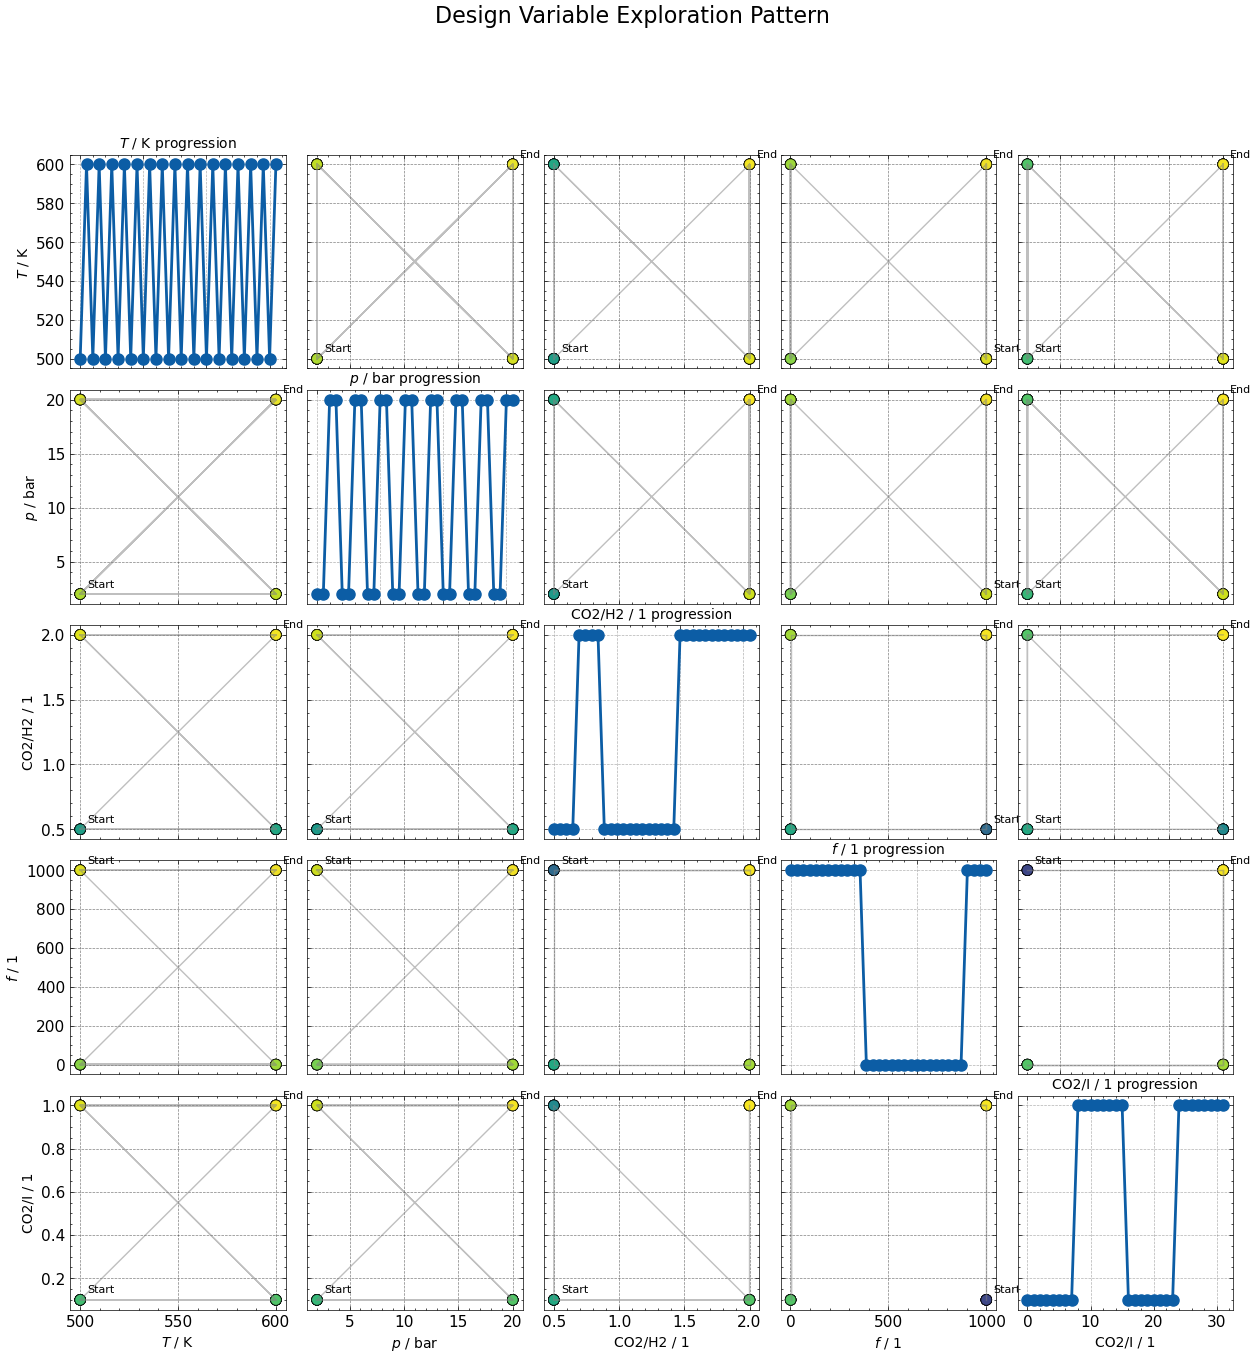

In [11]:
# create a 5x5 matrix plot with no gaps between the subplots
fig, axs = plt.subplots(
    5,
    5,
    figsize=(15, 15),
    sharex=False,
    sharey=False,
    gridspec_kw={"hspace": 0.1, "wspace": 0.1},
)

# Variable names for labeling
var_names = [r"$T$ / K", r"$p$ / bar", r"CO2/H2 / 1", r"$f$ / 1", r"CO2/I / 1"]

# Assuming proposals array exists with shape (n_experiments, 5)
n_experiments = proposals.shape[0]
experiment_order = np.arange(n_experiments)

for i in range(5):
    for j in range(5):
        ax = axs[i, j]

        if i == j:  # Diagonal: time series of each variable
            ax.plot(experiment_order, proposals[:, i], "o-", linewidth=2, markersize=8)
            ax.set_title(f"{var_names[i]} progression", fontsize=10, pad=5)
            ax.grid(True, alpha=0.3)
            if i == 4:  # Bottom row
                ax.set_xlabel("Experiment #")
        else:  # Off-diagonal: scatter plots
            # Color points by experiment order for temporal information
            scatter = ax.scatter(
                proposals[:, j],
                proposals[:, i],
                c=experiment_order,
                cmap="viridis",
                s=60,
                alpha=0.8,
                edgecolors="black",
                linewidth=0.5,
            )

            # Add trajectory lines
            ax.plot(
                proposals[:, j],
                proposals[:, i],
                "-",
                alpha=0.5,
                color="gray",
                linewidth=1,
            )

            # Label first and last points
            ax.annotate(
                "Start",
                (proposals[0, j], proposals[0, i]),
                xytext=(5, 5),
                textcoords="offset points",
                fontsize=8,
            )
            if n_experiments > 1:
                ax.annotate(
                    "End",
                    (proposals[-1, j], proposals[-1, i]),
                    xytext=(5, 5),
                    textcoords="offset points",
                    fontsize=8,
                )

        # Set labels only on edges
        if i == 4:  # Bottom row
            ax.set_xlabel(var_names[j], fontsize=10)
        if j == 0:  # Left column
            ax.set_ylabel(var_names[i], fontsize=10)

        # Remove tick labels for inner plots
        if i < 4:
            ax.set_xticklabels([])
        if j > 0:
            ax.set_yticklabels([])

plt.suptitle("Design Variable Exploration Pattern", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

## Quantify the information gain

In [12]:
import xarray

info_gains = []
for i in range(0, len(idatas)):
    klds = kl_divergence_between_models(
        idata_new=idatas[i],
        idata_old=idatas[i],
        key_new="posterior",
        key_old="_prior",
        var_names=[
            "k0",
            "Ea_k",
            "A_oh",
            "dH_oh",
            "A_h2",
            "dH_h2",
            "A_mix",
            "dH_mix",
            "sigma_r",
        ],
    )
    info_gains.append(klds)
kldses = []
for i, klds in enumerate(info_gains):
    print(klds)
    print(klds.sum())
    kldses.append(klds.sum())

[0.54641479 0.9933504  0.09781859 0.07160534 0.41480085 1.34871025
 0.23772173 1.02180253 0.68136857]
5.413593032047363
[ 0.53098554  1.30659003  0.05605194 -0.0053575   0.03922073  3.50710296
  0.02157374  1.73881033  0.0582734 ]
7.253251170566507
[1.18586845 0.07856036 0.02889855 0.06120005 0.88011944 0.03193591
 0.38157751 0.09043653 1.09135153]
3.8299483168283146
[ 0.31731704  0.22890365  0.0522716  -0.00349948  0.24605582  0.03175058
  0.22958623  0.11836064  0.30451185]
1.525257943884254
[2.51298246e-01 1.62297515e-01 7.34596729e-03 6.53901110e-03
 2.85569495e+01 1.20768654e-01 1.85657384e+01 9.61261248e-02
 2.11017743e-01]
47.978081114406656
[0.20853475 0.12033582 0.04112294 0.04699874 0.63148366 0.00487708
 0.2000723  0.01880777 0.01853635]
1.2907694084036654
[2.86680023e+00 1.55933393e-02 4.61912408e-02 4.12157252e-02
 5.60980773e+00 1.84109163e-01 2.15455367e+01 6.10594282e-02
 1.12122843e+00]
31.49154203367149
[0.03641321 0.81920481 0.10315603 0.04819238 0.14050196 0.0067619

In [13]:
expected_KLDs = [
    trial["predicted_before_obs"]["expected_KLD"] for trial in exp_summary["trials"]
]

Text(0, 0.5, 'info gain as per KL divergence')

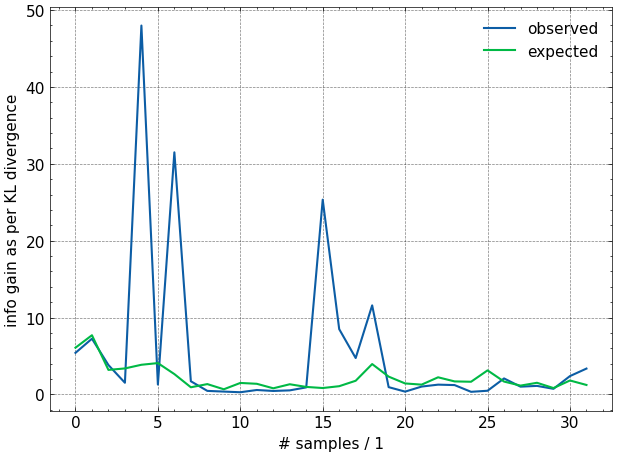

In [14]:
plt.plot(np.arange(len(kldses)), kldses, label="observed")
plt.plot(np.arange(len(kldses)), expected_KLDs, label="expected")
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

Text(0, 0.5, 'info gain as per KL divergence')

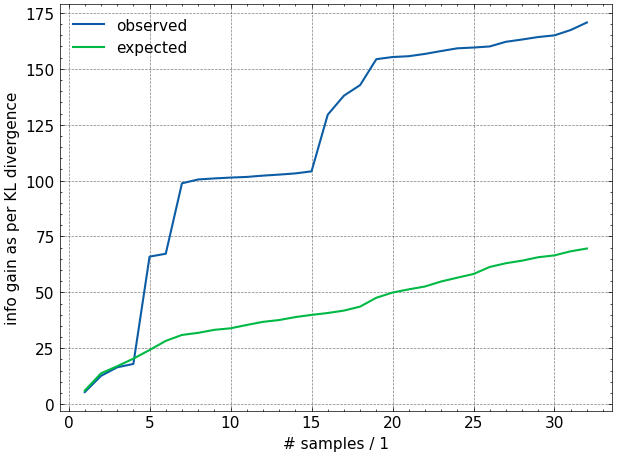

In [15]:
plt.plot(np.arange(len(kldses)) + 1, np.cumsum(kldses), label="observed")
plt.plot(np.arange(len(kldses)) + 1, np.cumsum(expected_KLDs), label="expected")
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

Text(0, 0.5, 'info gain as per KL divergence')

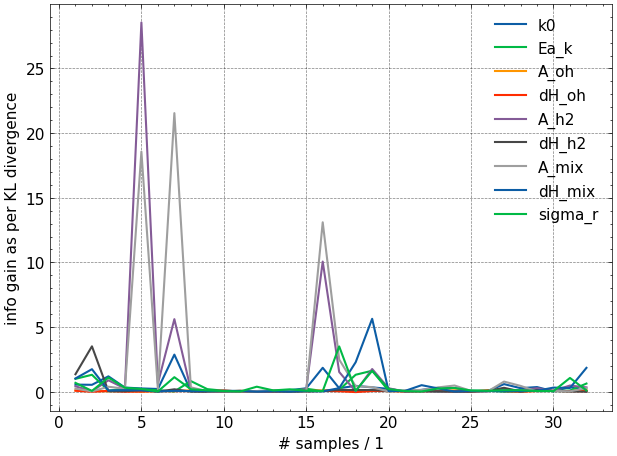

In [16]:
plt.plot(
    np.arange(len(kldses)) + 1,
    info_gains,
    label=[
        "k0",
        "Ea_k",
        "A_oh",
        "dH_oh",
        "A_h2",
        "dH_h2",
        "A_mix",
        "dH_mix",
        "sigma_r",
    ],
)
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

In [17]:
cum_info_gains = []
for i in range(0, len(idatas)):
    klds = kl_divergence_between_models(
        idata_new=idatas[i],
        idata_old=idatas[0],
        key_new="posterior",
        key_old="_prior",
        var_names=[
            "k0",
            "Ea_k",
            "A_oh",
            "dH_oh",
            "A_h2",
            "dH_h2",
            "A_mix",
            "dH_mix",
            "sigma_r",
        ],
    )
    cum_info_gains.append(klds)
cum_kldses = []
for i, klds in enumerate(cum_info_gains):
    print(klds)
    print(klds.sum())
    cum_kldses.append(klds.sum())

[0.48970137 0.90856442 0.05578564 0.08792907 0.40198958 1.34653413
 0.2318825  1.06136727 0.78551619]
5.369270158733936
[0.87916146 2.11906092 0.09074135 0.08686054 0.48121488 0.45327681
 0.28620825 0.56348526 0.92649744]
5.88650691156525
[1.4915708  2.39248949 0.08782488 0.05686243 0.9076611  0.5470473
 0.77916034 0.41702817 0.3976044 ]
7.0772489036800295
[2.07313144 2.74723704 0.10713481 0.06706823 1.33902837 0.39134879
 1.21152602 0.38919995 0.45844584]
8.784120493908784
[2.56223343 3.07566267 0.16343652 0.04945911 2.25235862 0.65364485
 1.92545729 0.39328948 0.74963163]
11.825173597038834
[2.59925848 2.94993771 0.04131913 0.10673567 1.95724795 0.63832835
 1.77121485 0.29315983 0.74963248]
11.106834444467996
[2.40123306 2.79546252 0.1102871  0.03076083 1.50341475 0.3953421
 1.21966381 0.1965489  0.66621001]
9.318923073513531
[2.29250359 2.74770415 0.0380025  0.0442048  1.41502856 0.37819651
 1.25502337 0.24609194 0.80885345]
9.225608871538158
[2.3441972  2.77910034 0.09614299 0.0616

Text(0, 0.5, 'info gain as per KL divergence')

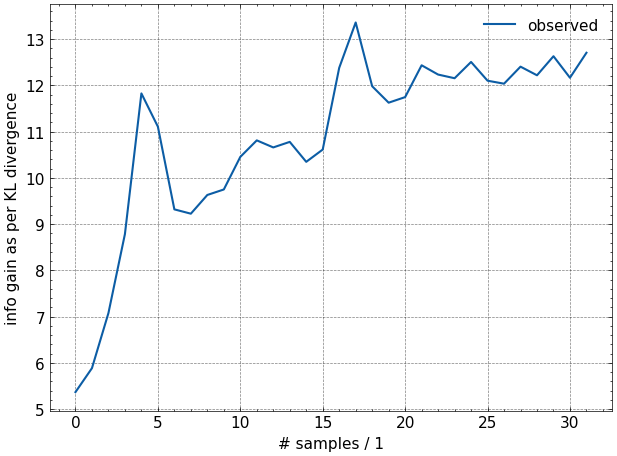

In [18]:
plt.plot(np.arange(len(cum_kldses)), cum_kldses, label="observed")
plt.legend()
plt.xlabel("# samples / 1")
plt.ylabel("info gain as per KL divergence")

In [19]:
from ipywidgets import Dropdown

print(list(idatas[0].posterior.data_vars))


@interact(
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    )
)
def interactive(key):
    az.plot_density(
        [idata for idata in idatas],
        group="posterior",
        var_names=key,
        shade=0.2,
    )

['k0', 'Ea_k', 'A_oh', 'dH_oh', 'A_h2', 'dH_h2', 'A_mix', 'dH_mix', 'sigma_r']


interactive(children=(Dropdown(description='Parameter:', options=('k0', 'Ea_k', 'A_oh', 'dH_oh', 'A_h2', 'dH_h…

In [20]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
    key=Dropdown(
        options=list(idatas[0].posterior.data_vars),
        value="k0",
        description="Parameter:",
    ),
)
def interactive(i, key):
    az.plot_dist_comparison(idatas[i], var_names=[key], figsize=(4, 4))

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), Dropdown(description='Parameter:',…

In [21]:
@interact(
    i=IntSlider(min=0, max=len(idatas) - 1, step=1, value=0, description="Iteration:"),
)
def interactive(i):
    axs = az.plot_pair(
        idatas[i],
        group="posterior",
        var_names=["k0", "Ea_k"],
        kind=["scatter", "kde"],
        point_estimate="median",
        marginals=True,
    ).flatten()
    axs[2].set(
        xlim=(8e-5, 1e-3),
        # xscale="log",
        ylim=(30e3, 130e3),
    )

interactive(children=(IntSlider(value=0, description='Iteration:', max=31), Output()), _dom_classes=('widget-i…

In [22]:
az.summary(idatas[-1], round_to=5)

arviz - WARNING - Shape validation failed: input_shape: (1, 4000), minimum_shape: (chains=2, draws=4)


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
k0[0],0.00036,0.00002,0.00032,0.00040,0.00000,0.00000,3960.46520,3712.14925,NaN
Ea_k[0],78868.30469,2489.56470,74143.48438,83470.99219,40.35427,28.63238,3785.34052,3767.19040,NaN
A_oh[0],1.03578,1.31203,0.02161,2.91921,0.02078,0.06161,3730.00328,3919.42846,NaN
dH_oh[0],9786.94531,13029.25293,246.15277,27445.78320,204.58004,969.08681,3930.23827,3881.35747,NaN
A_h2[0],0.41738,0.04914,0.32552,0.50894,0.00085,0.00060,3310.77746,3762.49558,NaN
dH_h2[0],-9459.41211,2009.74927,-13483.66211,-5894.40527,33.89899,23.96098,3495.16943,3837.31452,NaN
A_mix[0],0.94916,0.06511,0.82561,1.07176,0.00103,0.00073,4000.96981,4003.83708,NaN
dH_mix[0],-6714.05469,2252.86108,-10694.71973,-2297.85400,36.87592,25.72325,3720.11555,3786.84342,NaN
sigma_r[0],0.09460,0.01092,0.07454,0.11547,0.00018,0.00013,3737.05732,3863.32895,NaN
